# 京都大学 2026 理系 第4問 — Julia + Wolfram Engine で解く

## 問題

平面において，次の条件 $(\ast)$ を満たす正三角形の 1 辺の長さの最小値を求めよ。

$(\ast)$　1 辺の長さが $1$ の正方形であって，4 つの頂点がすべてその正三角形の内部または辺上にあるようなものが存在する。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。

In [1]:
include("wolfram_common.jl");     # MathLink の読み込みと，共通の関数（表示・変換）
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

## 1. 座標を設定する

**正方形を固定**し，そのまわりで正三角形を動かして考えます。

- 正方形の頂点：$(0,0),\ (1,0),\ (1,1),\ (0,1)$
- 正三角形：3 本の辺を「外向きの単位法線ベクトル $\vec{n}_k$ と，原点からの符号つき距離 $h_k$」で表します。

$$\text{辺 } k:\ \vec{n}_k\cdot(x,\ y) = h_k,\qquad \text{正三角形（内部と辺上）}:\ \vec{n}_k\cdot(x,\ y) \leqq h_k\quad(k = 1, 2, 3)$$

正三角形の向きを角 $\theta$ で表し，法線の向きを $\theta + 30^\circ,\ \theta + 150^\circ,\ \theta + 270^\circ$ とします（$\theta = 0$ のとき，3 本目の辺が下側にある水平な底辺）。

In [2]:
# Wolfram では角を th と書く。表示のときに θ に直す
ttex(w) = replace(tex(w), "\\text{th}" => "\\theta", "\\text{h1}" => "h_1", "\\text{h2}" => "h_2", "\\text{h3}" => "h_3")

nstr(k) = "{Cos[th + $(4k - 3) Pi/6], Sin[th + $(4k - 3) Pi/6]}"      # 辺 k の外向き法線（文字列）
for k in 1:3
    showtex("\\vec{n}_$k = " * replace(ttex(wparse(nstr(k))), "\\{" => "(", "\\}" => ")"))
end

### 正三角形の 1 辺の長さを $h_1, h_2, h_3$ で表す

2 本の辺の交点として頂点を求め，頂点間の距離を計算します。

In [3]:
# 辺 i と辺 j の交点
corner(i, j) = "({x, y} /. First[Solve[{Dot[$(nstr(i)), {x, y}] == h$i, Dot[$(nstr(j)), {x, y}] == h$j}, {x, y}]])"

Tw = weval(wparse("FullSimplify[{$(corner(1, 2)), $(corner(2, 3)), $(corner(3, 1))}]"))      # 3 頂点
sides = [weval(W"FullSimplify"(W"Sqrt"(W"Dot"(W"Subtract"(Tw.args[i], Tw.args[j]), W"Subtract"(Tw.args[i], Tw.args[j]))),
                               W`h1 + h2 + h3 > 0`)) for (i, j) in [(1, 2), (2, 3), (3, 1)]]
showtex("\\text{3 辺の長さ}:\\quad " * join(ttex.(sides), ",\\quad "))
Lw = sides[1];

3 辺とも同じ長さ（確かに正三角形）で，1 辺の長さは

$$L = \frac{2}{\sqrt3}\,(h_1 + h_2 + h_3)$$

です。$\theta$ によらず，$h_1 + h_2 + h_3$ だけで決まります。**どの $h_k$ を小さくしても $L$ は小さくなる**ことが分かります。

## 2. 辺が正方形に触れていなければ，もっと小さくできる

正方形の 4 頂点がすべて正三角形に含まれる条件は，各辺 $k$ について，4 頂点 $\mathrm{V}$ すべてが $\vec{n}_k\cdot\mathrm{V} \leqq h_k$ を満たすこと，つまり

$$h_k \geqq s_k(\theta),\qquad s_k(\theta) = \max_{\mathrm{V}}\ \vec{n}_k\cdot\mathrm{V}$$

です。$h_k > s_k(\theta)$ なら，辺 $k$ は正方形のどの頂点にも触れていません。そのときは辺 $k$ を内側に平行移動して $h_k$ を小さくでき，$L$ も小さくなります。

したがって，**向き $\theta$ を決めたときに最小の正三角形は，3 本の辺すべてが正方形の頂点を通るもの**（$h_k = s_k(\theta)$）で，その 1 辺の長さは

$$L(\theta) = \frac{2}{\sqrt3}\left\{s_1(\theta) + s_2(\theta) + s_3(\theta)\right\}$$

In [4]:
Vs = [(0, 0), (1, 0), (1, 1), (0, 1)]                                   # 正方形の頂点
sstr(k) = "Max[" * join(["Dot[$(nstr(k)), {$(v[1]), $(v[2])}]" for v in Vs], ", ") * "]"      # s_k(θ)

sw  = [weval(wparse(sstr(k))) for k in 1:3]
Lθw = weval(W"Times"(W`2/Sqrt[3]`, W"Plus"(sw...)))
showtex("L(\\theta) = " * ttex(Lθw))

### $L(\theta)$ のグラフ

Julia の関数にして，$0^\circ \leqq \theta \leqq 120^\circ$ でグラフをかきます（正三角形は $120^\circ$ 回すと元に戻る）。

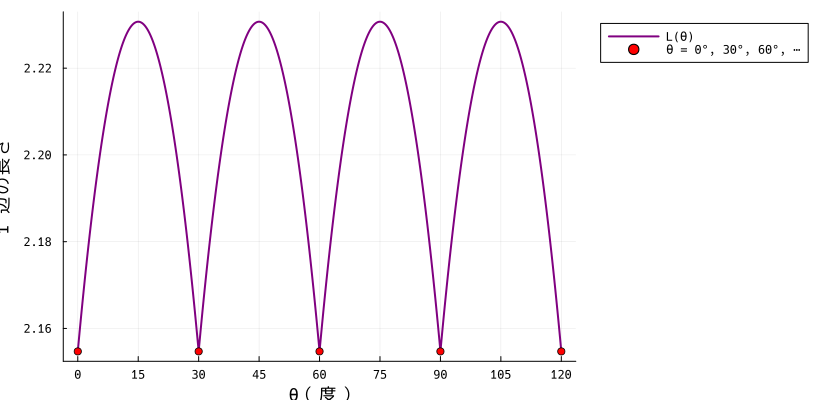

In [5]:
L = to_function(Lθw, :th)

deg = range(0, 120; length=1201)
plot(deg, L.(deg2rad.(deg)); lw=2, color=:purple, label="L(θ)", xlabel="θ（度）", ylabel="1 辺の長さ",
     xticks=0:15:120, size=(820, 400), legend=:outertopright)
scatter!(0:30:120, L.(deg2rad.(0:30:120)); color=:red, label="θ = 0°, 30°, 60°, …")

$L(\theta)$ は $30^\circ$ ごとに同じ形をくり返し，$\theta = 0^\circ,\ 30^\circ,\ 60^\circ,\ \dots$ で最小，その真ん中（$15^\circ,\ 45^\circ,\ \dots$）で最大になっています。

### 図で見る

$\theta = 0^\circ,\ 10^\circ,\ 15^\circ,\ 30^\circ$ のときの「最小の正三角形」をかき，正三角形の辺上にある正方形の頂点を赤丸で示します。

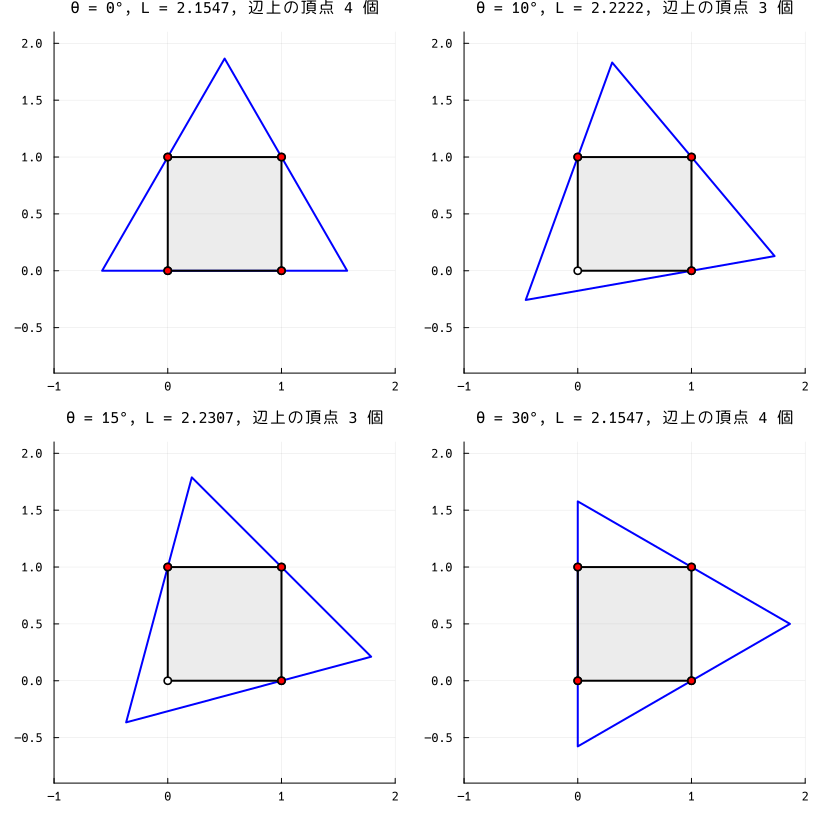

In [6]:
tri = to_function(Tw, :th, :h1, :h2, :h3)                     # 正三角形の 3 頂点（Julia の関数）
s   = [to_function(sw[k], :th) for k in 1:3]                 # s_k(θ)
nrm(k, th) = (cos(th + (4k - 3) * π / 6), sin(th + (4k - 3) * π / 6))

# 頂点 v が辺 k の上にあるか
onside(v, k, th) = abs(nrm(k, th)[1] * v[1] + nrm(k, th)[2] * v[2] - s[k](th)) < 1e-9

function plottri(d)
    th = deg2rad(d)
    T  = Float64.(stack(tri(th, s[1](th), s[2](th), s[3](th))))            # 列が頂点
    on = [v for v in Vs if any(onside(v, k, th) for k in 1:3)]             # 辺上にある頂点
    p = plot(T[1, [1, 2, 3, 1]], T[2, [1, 2, 3, 1]]; lw=2, color=:blue, label="", aspect_ratio=:equal,
             title="θ = $(d)°, L = $(round(L(th); digits=4)), 辺上の頂点 $(length(on)) 個", titlefontsize=10,
             xlims=(-1.0, 2.0), ylims=(-0.9, 2.1))
    plot!(p, [0, 1, 1, 0, 0], [0, 0, 1, 1, 0]; lw=2, color=:black, fillrange=0, fillalpha=0.15, fillcolor=:gray, label="")
    scatter!(p, first.(Vs), last.(Vs); markercolor=:white, markerstrokecolor=:black, label="")
    scatter!(p, first.(on), last.(on); color=:red, label="")
end

plot([plottri(d) for d in (0, 10, 15, 30)]...; layout=(2, 2), size=(820, 820))

- $\theta = 10^\circ,\ 15^\circ$ のように半端な向きでは，辺上にある頂点は **3 個**（各辺に 1 個ずつ）で，残り 1 個は内部にあります。このときは向きを少し変えると $L$ が小さくなります。
- $\theta = 0^\circ,\ 30^\circ$ では，正方形の 1 辺が正三角形の辺に重なり，**4 個すべて**が辺上にあります。ここで $L$ が最小です。

予想どおり「4 点すべてが正三角形の辺上にある」ときが最小になっていそうです。

## 3. 最小値を求める

$0 \leqq \theta \leqq 30^\circ$ の範囲で $L(\theta)$ を簡単にします（この範囲では `Max` がどの頂点でとられるかが決まる）。

In [7]:
L1w = weval(W"FullSimplify"(Lθw, W`0 < th < Pi/6`))
showtex("L(\\theta) = " * ttex(L1w) * "\\qquad \\left(0 \\leqq \\theta \\leqq \\frac{\\pi}{6}\\right)")

d2w = weval(W"FullSimplify"(W"D"(L1w, W`{th, 2}`)))
showtex("L''(\\theta) = " * ttex(d2w))

$0 \leqq \theta \leqq \dfrac{\pi}{6}$ では $\cos\theta > 0$，$\sin\theta \geqq 0$ なので $L''(\theta) < 0$，つまりグラフは**上に凸**です。上に凸な関数の最小値は区間の端でとるので，両端の値を調べます。

In [8]:
at(v) = weval(W"FullSimplify"(W"ReplaceAll"(L1w, W"Rule"(W"th", v))))
showtex("L(0) = " * tex(at(0)) * ",\\qquad L\\left(\\frac{\\pi}{6}\\right) = " * tex(at(W`Pi/6`)) *
        ",\\qquad L\\left(\\frac{\\pi}{12}\\right) = " * tex(at(W`Pi/12`)))

mn = weval(W"Minimize"(W"List"(Lθw, W`0 <= th <= Pi/6`), W"th"))      # Max のままの式を Wolfram で最小化
Lmin = weval(W"FullSimplify"(mn.args[1]))
showtex("\\text{最小値} = " * tex(Lmin) * " \\approx " * string(round(to_value(Lmin); digits=6)))

### 検算：Julia で全部の向きを調べる

$L(\theta)$ が $30^\circ$ ごとのくり返しであることと，全体の最小値を，細かい格子で確かめます。

In [9]:
θs = range(0, 2π; length=100_001)
println("L(θ + 30°) = L(θ) か： ", maximum(abs(L(t + π/6) - L(t)) for t in θs) < 1e-12)
println("格子での最小値 = ", minimum(L.(θs)), "   1 + 2/√3 = ", 1 + 2 / sqrt(3))

L(θ + 30°) = L(θ) か： true
格子での最小値 = 2.154700538379252   1 + 2/√3 = 2.1547005383792515


## 答え

$$\text{最小値}\quad 1 + \frac{2}{\sqrt3} = \frac{3 + 2\sqrt3}{3}$$

**まとめ**

1. 正三角形の 1 辺の長さは $L = \dfrac{2}{\sqrt3}(h_1 + h_2 + h_3)$。正方形の頂点に触れていない辺があれば，その辺を内側に平行移動して $L$ を小さくできる。→ 最小のとき，3 本の辺はどれも正方形の頂点を通る。
2. そのうえで向き $\theta$ を動かすと，$L(\theta)$ は各区間 $\left[0,\ \dfrac{\pi}{6}\right]$ などで上に凸。→ 区間の内部（辺上の頂点が 3 個）では最小にならず，区間の端（正方形の 1 辺が正三角形の辺に重なり，4 頂点すべてが辺上）で最小。
3. そのとき $L = 1 + \dfrac{2}{\sqrt3}$。底辺に正方形の 1 辺（長さ $1$）が乗り，その両側に $\dfrac{1}{\tan 60^\circ} = \dfrac{1}{\sqrt3}$ ずつ余る形です。